## KINH TẾ LƯỢNG TÀI CHÍNH
MODULE 1 | BÀI 1

---

# **PHÂN TÍCH HỒI QUY TUYẾN TÍNH**

|  |  |
|:---|:---|
|**Thời gian đọc** |  60 phút |
|**Kiến thức nền** | Đại số tuyến tính, thống kê bậc đại học  |
|**Từ khóa** | Biến nội sinh (biến phụ thuộc), biến ngoại sinh (biến độc lập), biểu đồ phân tán, điểm ngoại lai, <br> điểm đòn bẩy (leverage), hồi quy tuyến tính bình phương tối thiểu thông thường (OLS), tham số (hệ số), R2, R2 hiệu chỉnh, <br> khoảng cách Cook (Cook's D), điểm ảnh hưởng, biểu đồ ảnh hưởng |


---

*Trong khóa học này, chúng ta dùng kinh tế lượng để phân tích cách dữ liệu tài chính vận động và tác động lẫn nhau. Kinh tế lượng dùng toán học và suy diễn thống kê để khám phá mối quan hệ giữa các biến tài chính. Có nhiều kỹ thuật và mô hình trong kinh tế lượng. Trong bài này, chúng ta bắt đầu bằng phân tích hồi quy tuyến tính để minh họa một số khái niệm cơ bản. Hồi quy tuyến tính là kỹ thuật phân tích được dùng thường xuyên nhất trong tài chính và là nền tảng của nhiều lý thuyết kinh tế lượng nâng cao hơn. Bài này cũng trình bày các bước cơ bản để thực hiện phân tích hồi quy tuyến tính; những bước này áp dụng được cho các phân tích kinh tế lượng nâng cao sau này. Người đọc cần có kiến thức thống kê bậc đại học.*

In [1]:
# Thư viện
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

plt.rcParams["figure.figsize"] = (12, 9)

## **1. Chuẩn bị một dự án phân tích hồi quy tuyến tính**

Giả sử bạn làm việc cho một công ty quản lý tài sản với vai trò chuyên viên phân tích cổ phiếu. Sếp yêu cầu bạn tìm hiểu nguyên nhân khiến giá cổ phiếu Coca Cola (NYSE: KO) tăng gần đây và xem giá còn tiềm năng tiếp tục tăng hay không. Trong tình huống này, bạn sẽ làm gì? Có ba bước cần nghĩ tới:

### **1.1 Xác định các yếu tố có thể ảnh hưởng đến giá cổ phiếu KO**

Bạn có thể nghiên cứu để xác định các yếu tố có thể tác động đến giá cổ phiếu. Đó có thể là doanh thu của công ty, hoặc toàn thị trường chứng khoán đang đi lên. Dựa trên nghiên cứu và hiểu biết về công ty, có thể còn những yếu tố khác giải thích việc giá cổ phiếu *KO* tăng. Khi đã xác định được các yếu tố, bạn có thể bắt đầu thu thập dữ liệu để phân tích.

### **1.2. Lượng hóa mối quan hệ giữa giá cổ phiếu KO và các yếu tố đã chọn**

Khi đã xác định được các yếu tố và thu thập dữ liệu, chúng ta cần một hệ thống cho biết mỗi yếu tố ảnh hưởng đến giá cổ phiếu như thế nào. Ví dụ, ta muốn biết không chỉ việc doanh thu biến động có làm giá cổ phiếu tăng hay giảm, mà còn giá cổ phiếu sẽ dịch chuyển bao nhiêu khi doanh thu thay đổi. Ta cần xây dựng một mô hình để có thông tin này. Trong bài này, chúng ta dùng phân tích hồi quy tuyến tính để xây dựng mô hình. Sau đó, ta đánh giá mô hình chính xác đến đâu và điều chỉnh cho đến khi có một mô hình thỏa đáng.

### **1.3 Dự báo giá cổ phiếu trong tương lai**

Sau khi có mô hình hồi quy, ta có thể tạo nhiều kịch bản để dự báo biến động giá cổ phiếu. Ví dụ, nếu doanh thu của *KO* là một trong các yếu tố trong mô hình, ta có thể mô phỏng giá cổ phiếu sẽ thay đổi bao nhiêu khi doanh thu tăng 0,5%, 1% và 2%. Bài tập này giúp ta dự báo tiềm năng tăng giá của *KO*.

## **2. Biến nội sinh và biến ngoại sinh**

Giả sử bạn đã xác định ba yếu tố có tác động lớn nhất đến giá cổ phiếu *KO*: doanh thu của *KO*, giá cổ phiếu Pepsi và chỉ số Dow Jones Industrial Average. Chúng ta dùng ba yếu tố này để tạo mô hình hồi quy tuyến tính dự báo giá đóng cửa ngày kế tiếp của *KO*. Lý thuyết tài chính cho biết lợi suất vượt trội (excess return) của cổ phiếu là biến phân tích tốt hơn giá thực tế. Lợi suất vượt trội là lợi suất thực tế trừ lãi suất phi rủi ro (thường là lãi suất tín phiếu kho bạc). Vì vậy, chúng ta chuyển mọi biến thành lợi suất hoặc tỷ lệ. Trong bộ dữ liệu mô hình hóa, ta có các biến sau:

> Lợi suất vượt trội của cổ phiếu *KO* (%) <br>
> Tăng trưởng doanh thu của *KO* (%) <br>
> Lợi suất vượt trội của chỉ số *DOW 30* (%) <br>
> Lợi suất vượt trội của cổ phiếu *Pepsi* (%)

Để dùng các biến có thể so sánh được khi mô hình hóa, mọi biến đều là tỷ lệ theo quý (lợi suất vượt trội theo quý và tăng trưởng doanh thu theo quý).

Khi đã có bộ dữ liệu, ta cần quyết định biến nào là biến nội sinh và biến nào là biến ngoại sinh. **Biến nội sinh** (còn gọi là **biến phụ thuộc**) là biến có giá trị được xác định bởi mô hình. **Biến ngoại sinh** (còn gọi là **biến độc lập**) là biến có giá trị được xác định bên ngoài mô hình hoặc được cho trước. Trong trường hợp của ta, ta muốn xây dựng mô hình hồi quy để hiểu và dự báo lợi suất vượt trội của *KO* sẽ biến động thế nào khi ba yếu tố thay đổi. Lợi suất vượt trội của *KO* là biến nội sinh. Ba biến còn lại là biến ngoại sinh vì giá trị của chúng không do mô hình quyết định.

## **3. Kiểm tra mối quan hệ giữa biến nội sinh và các biến ngoại sinh**

Sau khi xác định biến nội sinh và biến ngoại sinh cho mô hình hồi quy, ta dùng một số công cụ đồ họa để khảo sát mối quan hệ giữa các biến đã chọn. Bước này quan trọng vì các biểu đồ cho ta thông tin về cách cấu trúc mô hình hồi quy và quyết định có nên loại bỏ một số biến hoặc điểm dữ liệu hay không. Công cụ đồ họa ta dùng là **biểu đồ phân tán (scatter plot)**. Biểu đồ phân tán là đồ thị hai chiều, một biến nằm trên trục này và một biến nằm trên trục kia. Nó cho thấy mối quan hệ giữa hai biến. Vậy biểu đồ phân tán dùng để làm gì?

Thứ nhất, biểu đồ phân tán giúp kiểm tra mối quan hệ tuyến tính giữa biến nội sinh và các biến ngoại sinh. Một trong các giả định khi chạy hồi quy là biến nội sinh có quan hệ tuyến tính với các biến ngoại sinh. Nhìn biểu đồ phân tán, ta xác định được có thể vẽ một đường thẳng mà phần lớn các điểm nằm quanh nó hay không.

Thứ hai, biểu đồ phân tán giúp kiểm tra tính độc lập giữa biến nội sinh và các biến ngoại sinh. Tiếp nối đoạn trước, nếu đường thẳng vẽ được là đường nằm ngang hoặc thẳng đứng thì dù giá trị của một biến thay đổi bao nhiêu, giá trị của biến kia vẫn luôn nằm trong một khoảng hẹp. Khi đó hai biến độc lập với nhau. Nếu một biến ngoại sinh độc lập với biến nội sinh, ta nên loại biến ngoại sinh này khỏi mô hình.

Cuối cùng, biểu đồ phân tán giúp tìm các điểm cực trị tách biệt rõ với các điểm còn lại. Có hai loại điểm cực trị. Loại thứ nhất là điểm ngoại lai. **Điểm ngoại lai (outlier)** là điểm không theo xu hướng chung của các điểm khác. Loại thứ hai là điểm đòn bẩy. **Điểm đòn bẩy (leverage point)** có giá trị cực trị ở các biến ngoại sinh. Cả hai loại có thể ảnh hưởng hoặc không ảnh hưởng đến kết quả ước lượng của mô hình hồi quy. Hãy thử chạy một mô hình có các điểm này và một mô hình không có, rồi so sánh hai kết quả để xem các điểm cực trị có quyết định kết quả cuối cùng hay không.

**Hình 2: Biểu đồ phân tán**—**Lợi suất vượt trội của cổ phiếu KO so với lợi suất vượt trội của chỉ số Dow 30**

In [2]:
# Tải bộ dữ liệu
data_set = pd.read_csv("fin_data_set.csv")

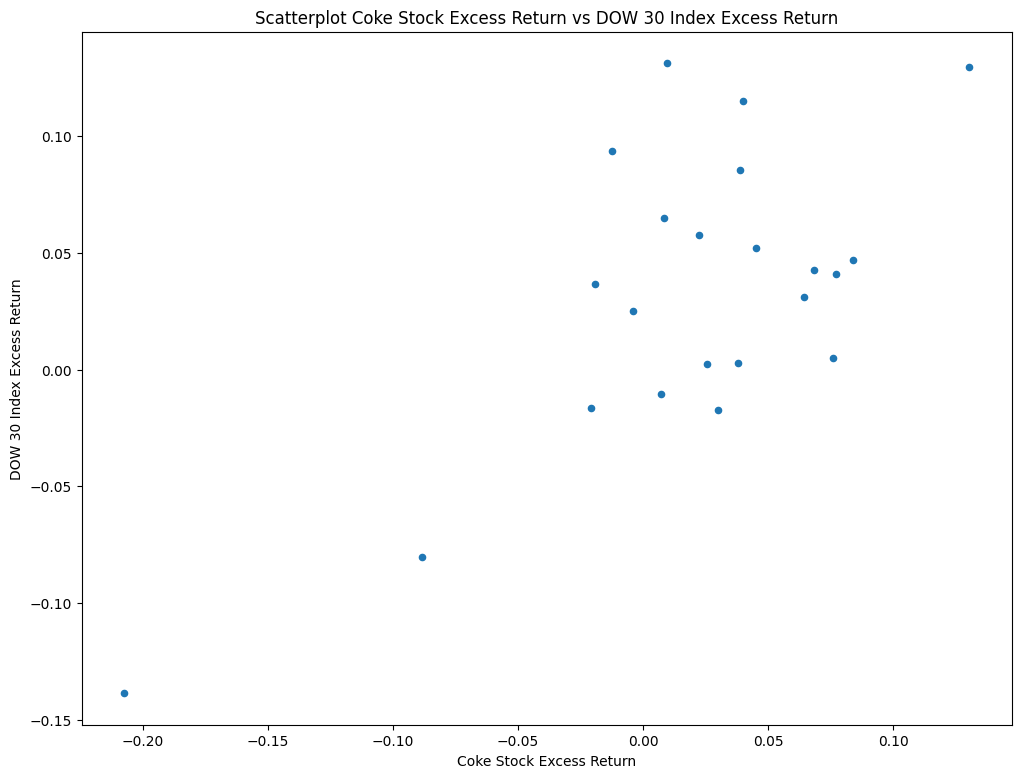

In [3]:
# Vẽ biểu đồ phân tán
scatt = data_set.plot.scatter(
    x="Coke_Q_EX_R",
    y="Dow_Q_EX_R",
    title="Biểu đồ phân tán: lợi suất vượt trội cổ phiếu Coke so với chỉ số DOW 30",
)
scatt.set(xlabel="Lợi suất vượt trội cổ phiếu Coke", ylabel="Lợi suất vượt trội chỉ số DOW 30")
plt.show()

Biểu đồ phân tán ở Hình 2 cho thấy lợi suất vượt trội của cổ phiếu *KO* và của chỉ số *Dow 30* có xu hướng đi cùng chiều trong bộ dữ liệu của ta. Có thể vẽ một đường thẳng từ góc dưới bên trái lên góc trên bên phải. Có hai điểm cực trị trên biểu đồ, nhưng chúng nằm dọc theo đường thẳng này.

Ta cũng có thể dùng thước đo **tương quan Pearson** để kiểm tra mối quan hệ tuyến tính của hai biến. Giá trị của tương quan Pearson nằm giữa $-1$ và $1$. Nếu giá trị của hai biến có xu hướng đi cùng chiều thì tương quan dương. Nếu hai biến có xu hướng đi ngược chiều thì tương quan âm. Tương quan bằng $1$ nghĩa là hai biến có quan hệ tuyến tính dương hoàn hảo.

**Hình 3: Ma trận biểu đồ gồm histogram, tương quan và biểu đồ phân tán cho các biến độc lập và biến phụ thuộc**

In [4]:
# Hàm tính hệ số tương quan giữa hai mảng


def corr(x, y, **kwargs):
    # Tính giá trị
    coef = np.corrcoef(x, y)[0][1]
    # Tạo nhãn
    label = r"$\rho$ = " + str(round(coef, 2))

    # Thêm nhãn vào biểu đồ
    ax = plt.gca()
    ax.annotate(label, xy=(0.3, 0.15), size=20, xycoords=ax.transAxes)

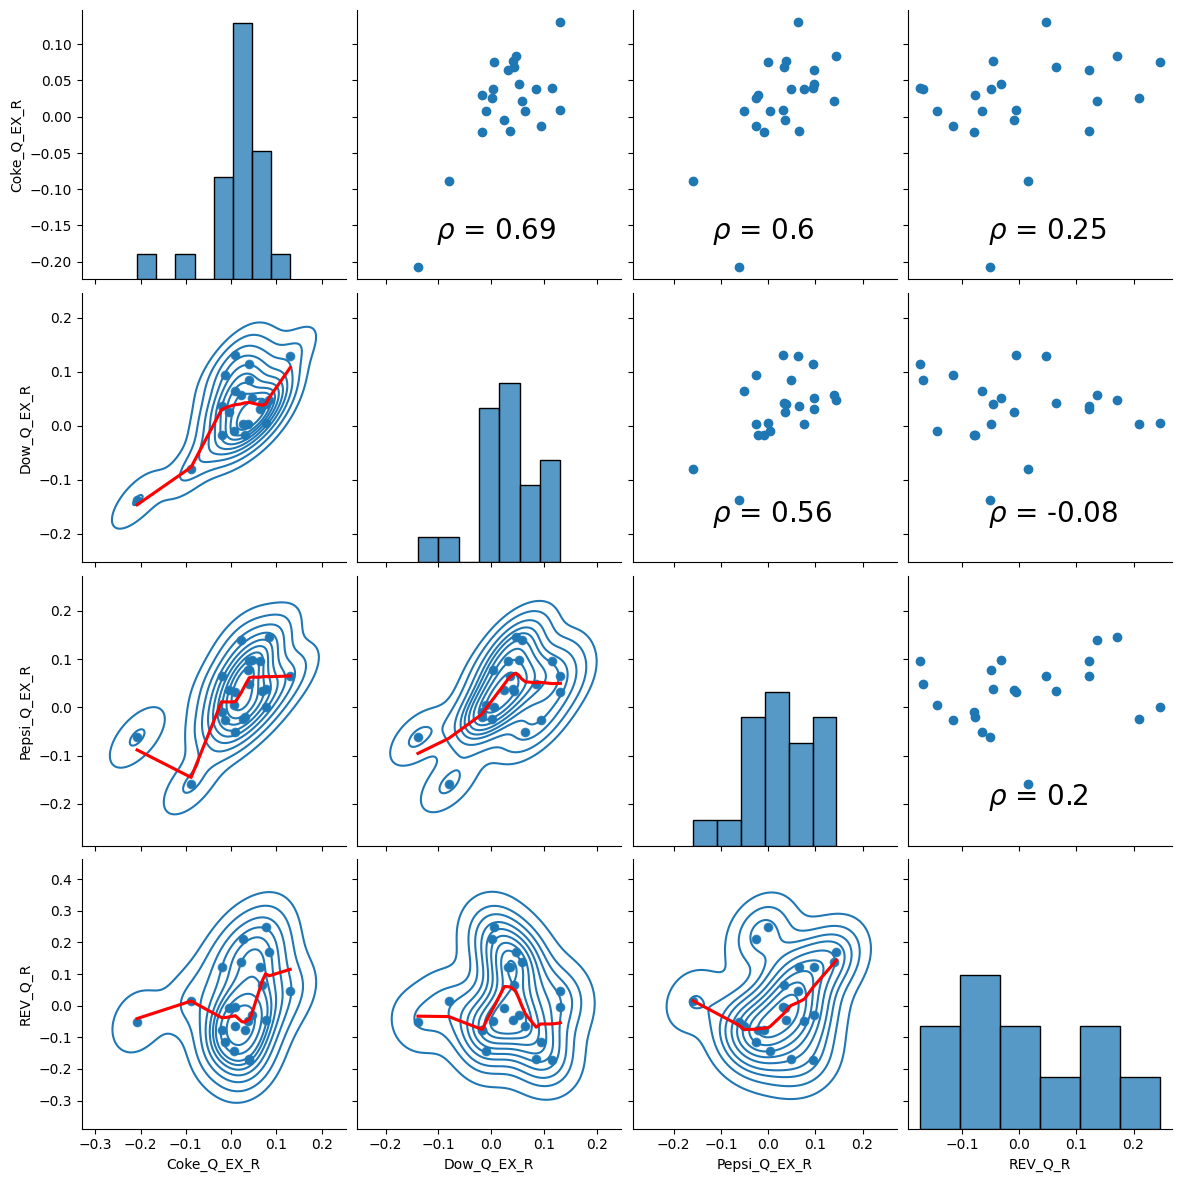

In [5]:
# Tạo pairplot mặc định
grid = sns.pairplot(
    data_set, vars=["Coke_Q_EX_R", "Dow_Q_EX_R", "Pepsi_Q_EX_R", "REV_Q_R"], height=3
)

# Vẽ biểu đồ phân tán và hệ số tương quan Pearson ở tam giác trên
grid = grid.map_upper(plt.scatter)
grid = grid.map_upper(corr)

# Vẽ histogram trên đường chéo
# grid = grid.map_diag(plt.hist)

# Vẽ biểu đồ mật độ và đường hồi quy ở tam giác dưới
grid = grid.map_lower(sns.kdeplot)
grid = grid.map_lower(sns.regplot, lowess=True, line_kws={"color": "red"})

> Giai đoạn dữ liệu: 2016Q2 – 2021Q3 <br>
> Nguồn dữ liệu: Yahoo Finance và website của Coca Cola <br>
> *KO_Q_EX_R*: lợi suất vượt trội theo quý của cổ phiếu *KO* <br>
> *Dow_Q_EX_R*: lợi suất vượt trội theo quý của chỉ số *DOW 30* <br>
> *Pepsi_Q_EX_R*: lợi suất vượt trội theo quý của cổ phiếu Pepsi <br>
> *REV_Q_R*: % thay đổi doanh thu theo quý của *KO* 

Hình 3 tóm tắt mối quan hệ giữa các biến trong phân tích lợi suất vượt trội của *KO*. Ma trận chia làm ba phần.

* Tam giác dưới bên trái của ma trận là các biểu đồ phân tán cho mọi cặp hai biến trong bốn biến.
* Các đồ thị trên đường chéo là histogram của bốn biến.
* Tam giác trên bên phải cho giá trị tương quan của mọi cặp hai biến trong bốn biến.

Biểu đồ phân tán giữa lợi suất *KO* và lợi suất *Dow* cho thấy hai biến có quan hệ tuyến tính dương tốt, cặp lợi suất *KO* và lợi suất Pepsi cũng vậy. Ở cả hai biểu đồ, các điểm dữ liệu ít nhiều tạo thành hình bầu dục. Đường màu đỏ cũng nghiêng lên. Các dấu hiệu này cho thấy hai biến này là lựa chọn tốt để mô hình hóa lợi suất *KO*. Ở biểu đồ phân tán giữa lợi suất *KO* và tăng trưởng doanh thu *KO*, ta không thấy hình bầu dục rõ ràng, và đường đỏ không thẳng, không dốc lên như hai biểu đồ kia. Giá trị tương quan ở tam giác trên bên phải cũng xác nhận thông tin từ các đồ thị. Lợi suất Dow và lợi suất Pepsi có tương quan dương tốt với lợi suất *KO*. Tuy nhiên, tăng trưởng doanh thu và lợi suất của *KO* có tương quan nhỏ hơn.

## **4. Ước lượng mô hình hồi quy**

Bây giờ ta bắt đầu xây dựng mô hình hồi quy. Phương pháp dùng ở đây là hồi quy tuyến tính bình phương tối thiểu thông thường (OLS). Có hai loại mô hình hồi quy OLS: **OLS đơn** và **OLS bội**. Nếu chỉ có một biến ngoại sinh so với một biến nội sinh thì gọi là hồi quy tuyến tính OLS đơn. Nếu có nhiều hơn một biến ngoại sinh so với một biến nội sinh thì gọi là hồi quy tuyến tính OLS bội. Vì mô hình của ta có ba biến ngoại sinh nên ta xây dựng hồi quy tuyến tính OLS bội.

Đây là mô hình hồi quy tuyến tính ta sẽ ước lượng:

$$ \text{KO excess return} = b_0 + b_1 \text{Dow excess return} + b_2 \text{Pepsi excess return} + b_3 \text{KO revenue growth} $$

$b_0$, $b_1$, $b_2$ và $b_3$ gọi là **tham số** hay **hệ số**. Ta dùng phương pháp OLS để ước lượng giá trị các tham số trong mô hình. Khi đã có giá trị các tham số từ phép tính OLS, ta gọi các giá trị đó là **ước lượng**.

**Hình 4: Kết quả hồi quy tuyến tính cho mô hình lợi suất vượt trội của KO**

In [6]:
# Kết quả hồi quy tuyến tính
result = smf.ols(
    "Coke_Q_EX_R ~ Dow_Q_EX_R + Pepsi_Q_EX_R + REV_Q_R", data=data_set
).fit()
result.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            Coke_Q_EX_R   R-squared:                       0.604
Model:                            OLS   Adj. R-squared:                  0.538
Method:                 Least Squares   F-statistic:                     9.150
Date:                Sat, 17 May 2025   Prob (F-statistic):           0.000677
Time:                        14:24:34   Log-Likelihood:                 38.570
No. Observations:                  22   AIC:                            -69.14
Df Residuals:                      18   BIC:                            -64.78
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
================================================================================
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -0.0080      0.011     -0.716      0.483      -0.032       0.015
Dow_Q_EX_R       0.6197      0.195      3.173      0.005       0.209       1.030
Pepsi_Q_EX_R     0.2187      0.179      1.221      0.238      -0.158       0.595
REV_Q_R          0.1435      0.088      1.632      0.120      -0.041       0.328
==============================================================================
Omnibus:                        1.644   Durbin-Watson:                   2.307
Prob(Omnibus):                  0.439   Jarque-Bera (JB):                1.411
Skew:                          -0.564   Prob(JB):                        0.494
Kurtosis:                       2.481   Cond. No.                         24.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [7]:
# Tham số với 6 chữ số có nghĩa
result.summary2().tables[1]

,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
Intercept,-0.008017,0.011189,-0.716476,0.482890,-0.031524,0.015490
Dow_Q_EX_R,0.619723,0.195287,3.173393,0.005261,0.209440,1.030006
Pepsi_Q_EX_R,0.218664,0.179107,1.220854,0.237893,-0.157627,0.594955
REV_Q_R,0.143481,0.087912,1.632093,0.120031,-0.041216,0.328178


Hình 4 cho thấy kết quả hồi quy. Hãy xem ước lượng của ba biến. Ước lượng có ý nghĩa gì? Ước lượng cho lợi suất vượt trội của Dow là 0,619723. Nghĩa là khi lợi suất vượt trội của Dow tăng 0,01 (1%), lợi suất vượt trội của *KO* sẽ tăng 0,00619723 (0,619723%).

## **5. Đánh giá mô hình**

Câu hỏi tiếp theo là mô hình ước lượng của ta tốt đến đâu. Có nhiều cách để đánh giá và kiểm định mức độ phù hợp của mô hình. Trước tiên ta xem hiệu quả của từng biến ngoại sinh trong mô hình, sau đó đánh giá mức độ phù hợp tổng thể.

### **5.1 Hiệu quả của từng biến ngoại sinh**

Trong phần hệ số của bảng kết quả có một cột tên *Pr(>|t|)*. Cột này cho giá trị $p$ của mỗi hệ số. Giá trị $p$ là thước đo cho biết biến ngoại sinh có giải thích được sự thay đổi của biến nội sinh hay không. Giá trị $p$ càng thấp thì biến ngoại sinh càng có khả năng giải thích biến nội sinh tốt. Trong nhiều dự án nghiên cứu, $0,05$ là mức xác định một biến ngoại sinh có ý nghĩa thống kê hay không. Từ kết quả của ta, biến ngoại sinh duy nhất có ý nghĩa là lợi suất vượt trội của *Dow* (giá trị $p$: 0,00526 < 0,05). Vậy có phải ta có thể bỏ hai biến còn lại khỏi mô hình? Có ít nhất hai điểm cần cân nhắc trước khi quyết định.

1. **Lợi suất vượt trội của KO và tăng trưởng doanh thu của KO có quan hệ tuyến tính hay không?**

Từ biểu đồ phân tán của hai biến, ta biết chúng có quan hệ tuyến tính yếu. Ta có thể biến đổi tăng trưởng doanh thu của *KO* thành một chuỗi dữ liệu khác rồi kiểm tra lại mối quan hệ không? Ta có thể thử lấy căn bậc hai hoặc logarit của tăng trưởng doanh thu *KO* rồi vẽ lại biểu đồ phân tán.

2. **Các biến ngoại sinh có tương quan với nhau không?**

Tương quan giữa lợi suất vượt trội của Dow và của Pepsi là 0,56 theo ma trận biểu đồ phân tán. Hai biến này có tương quan dương mức trung bình. Khi mô hình hồi quy có hai hoặc nhiều biến ngoại sinh tương quan với nhau, thường biến ngoại sinh nào có tương quan cao hơn với biến nội sinh sẽ "hấp thụ" toàn bộ khả năng giải thích của các biến ngoại sinh tương quan khác, khiến các biến kia không còn có ý nghĩa trong mô hình.

Hai điểm trên giúp ta suy nghĩ lại về cách chọn biến ngoại sinh và cách xử lý chúng trong mô hình. Ta sẽ bàn chi tiết hơn về hai điểm này và đưa ra các giải pháp khả thi trong các bài tiếp theo.

### **5.2 $R^2$ và $R^2$ hiệu chỉnh**

Bây giờ, hãy xem mức độ phù hợp chung của mô hình. $R^2$, hệ số xác định, là thước đo thường dùng để đánh giá độ phù hợp của mô hình. $R^2$ cho biết biến thiên của biến nội sinh được giải thích bao nhiêu bởi biến thiên của toàn bộ các biến ngoại sinh trong mô hình. Giá trị $R^2$ nằm giữa $0$ và $1$. Nếu $R^2$ bằng $1$, mô hình giải thích hoàn hảo hành vi lợi suất vượt trội của *KO*. Nói cách khác, với một bộ số của mọi biến ngoại sinh, mô hình tạo ra chính xác 100% số của biến nội sinh. Nhìn chung, $R^2$ càng cao thì mô hình càng phù hợp.

Trong mô hình của ta, $R^2$ là 0,604. Nghĩa là sự thay đổi của lợi suất vượt trội Dow, lợi suất vượt trội Pepsi và tăng trưởng doanh thu *KO* cùng nhau giải thích được 60% sự thay đổi của lợi suất vượt trội *KO*.

Nếu sếp cho rằng 0,604 chưa đạt yêu cầu, bạn có thể được yêu cầu cải thiện mô hình. Thông thường, thêm một biến ngoại sinh mới là điểm khởi đầu dễ nhất. Thêm nhiều biến ngoại sinh vào mô hình thường làm tăng $R^2$. Tuy nhiên, điều này có thể gây ra vấn đề quá khớp (overfitting). Quá khớp là gì? Là khi mô hình dự báo biến nội sinh rất tốt trên mẫu dữ liệu dùng để xây dựng mô hình, nhưng khi đưa một bộ dữ liệu khác có biến nội sinh và biến ngoại sinh vào mô hình, mô hình dự báo biến nội sinh kém với các giá trị mới của biến ngoại sinh.

**$R^2$ hiệu chỉnh** giúp xử lý vấn đề này. $R^2$ hiệu chỉnh nhằm điều chỉnh điều gì? Dù thêm biến độc lập mới vào mô hình hồi quy không bao giờ làm giảm $R^2$, nó làm mô hình phức tạp hơn. Nó cũng có thể gây quá khớp như mô tả ở trên. Do đó ta phải hỏi liệu độ phức tạp tăng thêm có xứng đáng hay không. Đây chính là việc $R^2$ hiệu chỉnh thực hiện. Giống $R^2$, $R^2$ hiệu chỉnh nằm giữa 0 và 1. $R^2$ hiệu chỉnh luôn thấp hơn $R^2$. $R^2$ hiệu chỉnh sẽ tăng nếu mức cải thiện khi thêm một biến ngoại sinh lớn hơn mức phạt do thêm một biến ngoại sinh vào mô hình.

Trong mô hình của ta, $R^2$ hiệu chỉnh là 0,538. Khó nói đây có phải là $R^2$ hiệu chỉnh tốt hay không. Trên thực tế, nhà nghiên cứu thường xây dựng nhiều phiên bản mô hình hồi quy rồi so sánh $R^2$ hiệu chỉnh của chúng để chọn mô hình cuối cùng. Xây dựng và tinh chỉnh mô hình là quá trình lặp; hiếm khi mô hình đầu tiên là mô hình tốt nhất cho một dự án.

## **6. Điểm ngoại lai và ảnh hưởng**

Ở phần trước, ta đã xem hiệu quả của các biến ngoại sinh trong mô hình và của cả mô hình. Trong phần này, ta xem xét tác động của từng điểm dữ liệu trong mẫu dùng để xây dựng mô hình hồi quy.

Ở phần biểu đồ phân tán, ta đã bàn về các giá trị cực trị trong bộ dữ liệu và giới thiệu điểm ngoại lai và điểm đòn bẩy. Không phải điểm nào trong số đó cũng ảnh hưởng đến kết quả mô hình hồi quy. Các ví dụ trực quan sau cho thấy một điểm dữ liệu cực trị có thể tác động đến kết quả hồi quy như thế nào. Chấm đỏ là điểm cực trị. Đường đen (trong mã là đường xanh) là đường hồi quy khi không có điểm cực trị. Đường đỏ là đường hồi quy khi có điểm cực trị.

**Hình 5: Tác động của một điểm ngoại lai lên kết quả mô hình hồi quy**

In [8]:
# Tạo 30 điểm ngẫu nhiên
np.random.seed(42)
n = 30
x = np.random.uniform(0, 5, n)
y = 1 + 3 * x + np.random.normal(0, 1, n)

# Thêm điểm ngoại lai tại (2.5, 17)
x_with_out = np.append(x, 2.5)
y_with_out = np.append(y, 17)

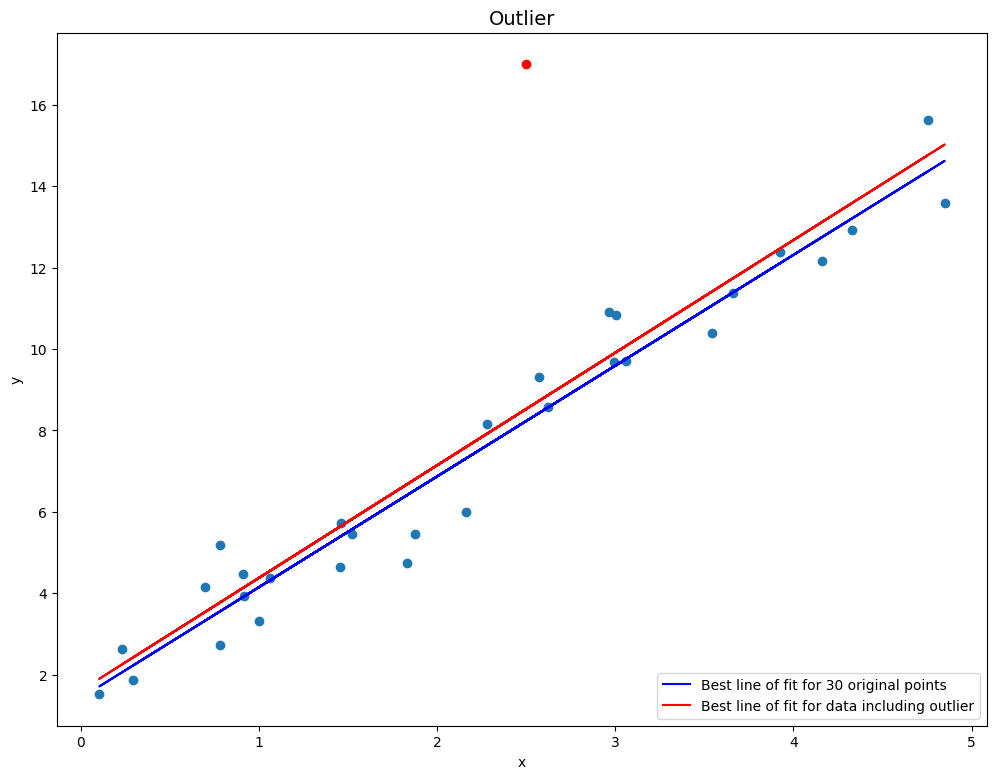

In [9]:
# Vẽ đường khớp nhất chỉ cho 30 điểm gốc (xanh) và cho 30 điểm + điểm ngoại lai (đỏ)
plt.title("Điểm ngoại lai", {"size": 14})
plt.plot(x, y, "o")  # biểu đồ phân tán
plt.plot(2.5, 17, "ro")  # Điểm ngoại lai màu đỏ

# đường khớp chỉ cho 30 điểm gốc
(a, b) = np.polyfit(x, y, 1)
plt.plot(x, a * x + b, "b-", label="Đường khớp nhất cho 30 điểm gốc")

# đường khớp cho 30 điểm + điểm ngoại lai
(ao, bo) = np.polyfit(x_with_out, y_with_out, 1)
plt.plot(
    x_with_out,
    ao * x_with_out + bo,
    "r-",
    label="Đường khớp nhất khi có điểm cực trị",
)

plt.xlabel("x")
plt.ylabel("y")
plt.legend(loc="lower right")
plt.show()

**Hình 6: Tác động của một điểm đòn bẩy không ảnh hưởng lên kết quả mô hình hồi quy**

In [10]:
# Thêm điểm đòn bẩy không ảnh hưởng tại (8, 25)
x_with_lev = np.append(x, 8)
y_with_lev = np.append(y, 25)

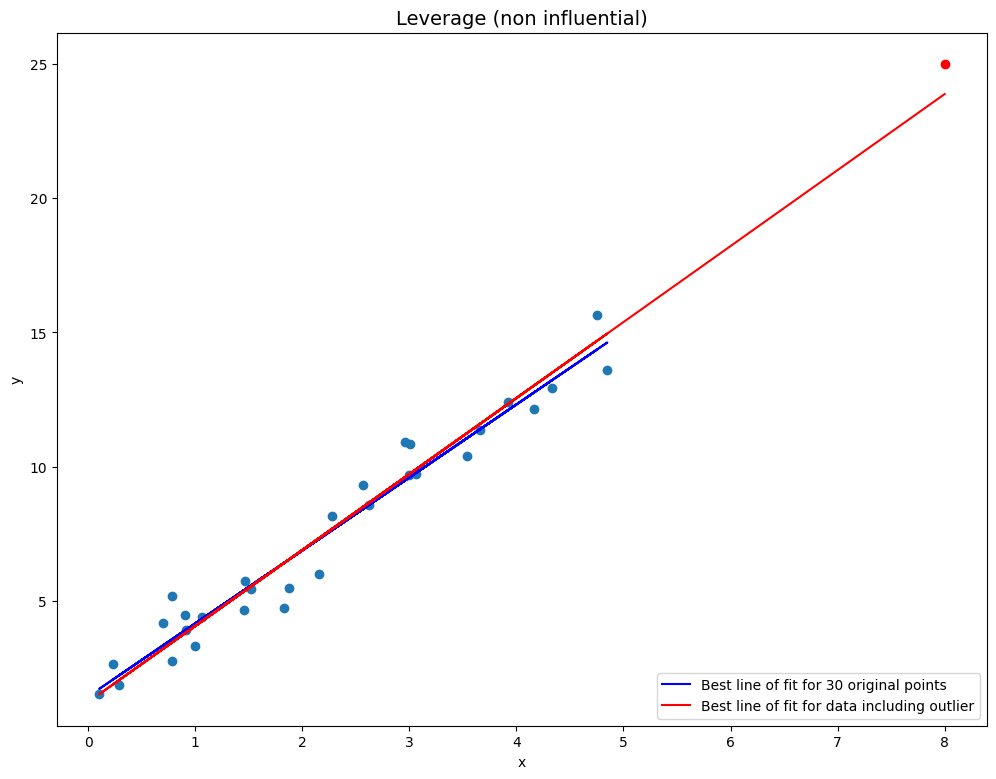

In [11]:
# Vẽ đường khớp nhất chỉ cho 30 điểm gốc (xanh) và cho 30 điểm + điểm đòn bẩy (đỏ)
plt.title("Điểm đòn bẩy (không ảnh hưởng)", {"size": 14})
plt.plot(x, y, "o")  # biểu đồ phân tán
plt.plot(8, 25, "ro")  # điểm đòn bẩy không ảnh hưởng màu đỏ

# đường khớp chỉ cho 30 điểm gốc
(a, b) = np.polyfit(x, y, 1)
plt.plot(x, a * x + b, "b-", label="Đường khớp nhất cho 30 điểm gốc")

# đường khớp cho 30 điểm + điểm ngoại lai
(al, bl) = np.polyfit(x_with_lev, y_with_lev, 1)
plt.plot(
    x_with_lev,
    al * x_with_lev + bl,
    "r-",
    label="Đường khớp nhất khi có điểm cực trị",
)

plt.xlabel("x")
plt.ylabel("y")
plt.legend(loc="lower right")
plt.show()

**Hình 7: Tác động của một điểm đòn bẩy có ảnh hưởng lên kết quả mô hình hồi quy**

In [12]:
# Thêm điểm đòn bẩy không ảnh hưởng tại (8, 25)
x_with_inf = np.append(x, 8)
y_with_inf = np.append(y, 5)

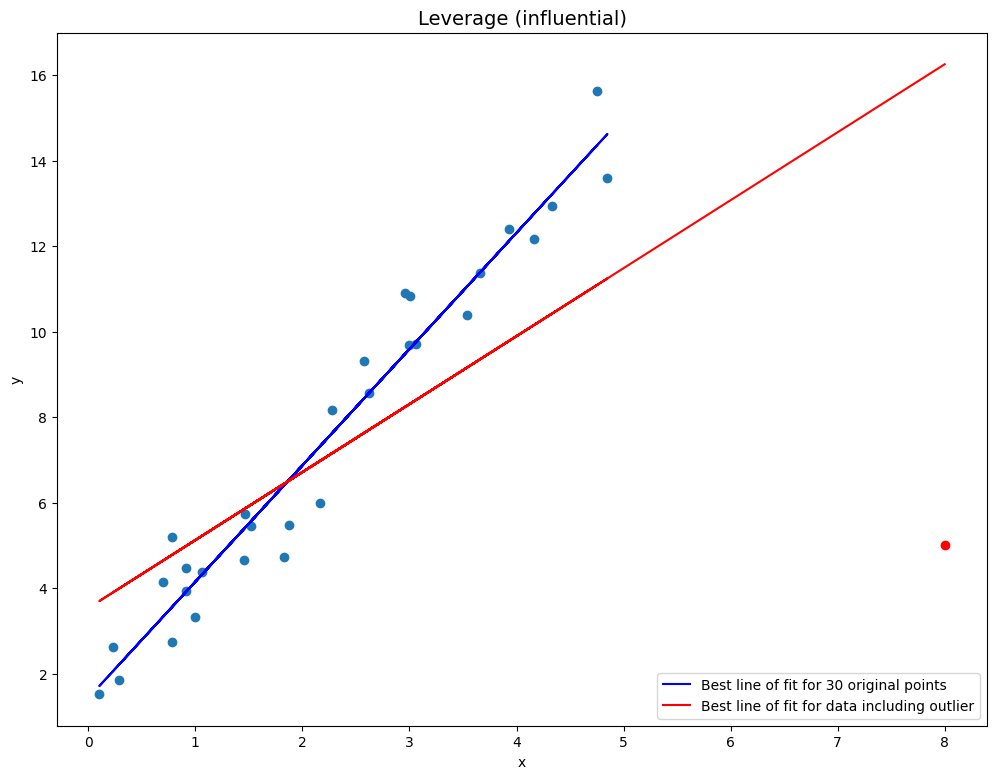

In [13]:
# Vẽ đường khớp nhất chỉ cho 30 điểm gốc (xanh) và cho 30 điểm + điểm đòn bẩy (đỏ)
plt.title("Điểm đòn bẩy (có ảnh hưởng)", {"size": 14})
plt.plot(x, y, "o")  # biểu đồ phân tán
plt.plot(8, 5, "ro")  # điểm đòn bẩy có ảnh hưởng màu đỏ

# đường khớp chỉ cho 30 điểm gốc
(a, b) = np.polyfit(x, y, 1)
plt.plot(x, a * x + b, "b-", label="Đường khớp nhất cho 30 điểm gốc")

# đường khớp cho 30 điểm + điểm ngoại lai
(ai, bi) = np.polyfit(x_with_inf, y_with_inf, 1)
plt.plot(
    x_with_inf,
    ai * x_with_inf + bi,
    "r-",
    label="Đường khớp nhất khi có điểm cực trị",
)

plt.xlabel("x")
plt.ylabel("y")
plt.legend(loc="lower right")
plt.show()

Ở Hình 5 và 6, ta thấy các đường hồi quy không thay đổi nhiều dù có hay không có điểm cực trị. Tuy nhiên, ở Hình 7, điểm cực trị làm thay đổi đáng kể kết quả hồi quy. Điểm cực trị có thể làm thay đổi đáng kể kết quả hồi quy được gọi là **điểm ảnh hưởng (influential point)**. Ta cần xác định các điểm ảnh hưởng trong bộ dữ liệu và tìm hiểu vì sao chúng cực trị (do một sự kiện đặc biệt hay do nhập sai dữ liệu) vì chúng có thể làm thay đổi kết quả hồi quy. Sau đó, ta chạy một mô hình có điểm ảnh hưởng và một mô hình không có điểm ảnh hưởng. Tiếp theo, ta so sánh kết quả hai mô hình và đánh giá kết quả nào phù hợp nhất với mục tiêu mô hình hóa.

Ta dùng **khoảng cách Cook (Cook's D)** để xác định các điểm ảnh hưởng trong bộ dữ liệu. *Cook's D* là thước đo sự khác biệt về dự báo giữa mô hình có một điểm dữ liệu và mô hình không có điểm dữ liệu đó. *Cook's D* càng cao thì điểm dữ liệu càng ảnh hưởng lớn đến việc ước lượng mô hình hồi quy. Thông thường, điểm dữ liệu có *Cook's D* lớn hơn 1 được coi là điểm ảnh hưởng.

**Hình 8: Biểu đồ ảnh hưởng cho bộ dữ liệu lợi suất vượt trội của KO**

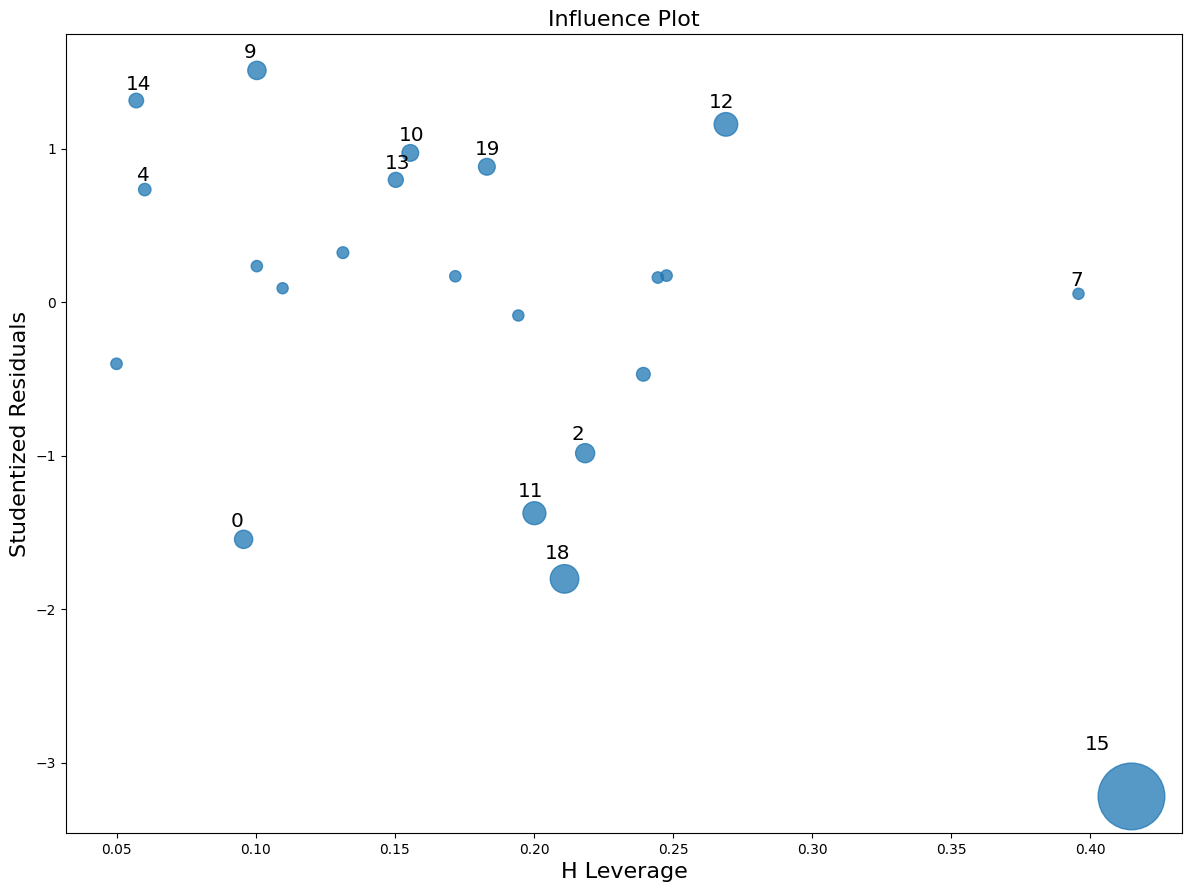

In [14]:
# Biểu đồ ảnh hưởng
fig = sm.graphics.influence_plot(result, criterion="cooks", alpha=0.5)
fig.tight_layout(pad=1.0)

In [15]:
# Tìm các điểm có ảnh hưởng lớn nhất
influence = result.get_influence()
inf_sum = influence.summary_frame().sort_values("cooks_d", ascending=False)
inf_sum.head(30)

,dfb_Intercept,dfb_Dow_Q_EX_R,dfb_Pepsi_Q_EX_R,dfb_REV_Q_R,cooks_d,standard_resid,hat_diag,dffits_internal,student_resid,dffits
15,-1.889683,2.264630,-0.430822,0.727270,1.208639,-2.611742,0.414779,-2.198763,-3.220750,-2.711472
18,-0.124451,-0.824470,0.459042,-0.147797,0.193197,-1.699993,0.210985,-0.879084,-1.803180,-0.932443
12,0.291357,0.075669,-0.235436,0.625953,0.121111,1.147373,0.269001,0.696022,1.158204,0.702592
11,-0.148011,0.132958,-0.454322,-0.227980,0.112746,-1.342453,0.200156,-0.671553,-1.375293,-0.687981
2,-0.159230,-0.367882,0.329489,0.120792,0.067781,-0.985067,0.218387,-0.520695,-0.984210,-0.520242
9,0.443542,-0.212676,-0.033271,-0.237637,0.059381,1.458782,0.100410,0.487366,1.509731,0.504388
0,-0.255128,0.021979,-0.109979,-0.299454,0.058620,-1.489205,0.095619,-0.484230,-1.545590,-0.502564
19,0.043818,0.341470,-0.123705,0.131239,0.044112,0.887378,0.183060,0.420059,0.881882,0.417457
10,0.279508,-0.201537,0.101374,-0.316001,0.043645,0.973571,0.155539,0.417827,0.972081,0.417188
13,0.179775,-0.221049,0.250137,-0.160919,0.028646,0.804747,0.150331,0.338500,0.796534,0.335045


Hình 8 là **biểu đồ ảnh hưởng (influence plot)**. Nó giúp ta hình dung *Cook's D* của mọi điểm dữ liệu. Trục ngang của biểu đồ là giá trị hat. Giá trị hat đo sự khác biệt giữa các giá trị ngoại sinh của một điểm dữ liệu và trung bình các giá trị ngoại sinh trong bộ dữ liệu. Trục đứng của biểu đồ là phần dư studentized. Đây là phần dư chuẩn hóa từ giá trị nội sinh dự báo của điểm dữ liệu theo mô hình. Các bong bóng trên biểu đồ thể hiện độ lớn của *Cook's D* của mỗi điểm. Bong bóng càng lớn thì *Cook's D* của điểm dữ liệu càng cao.

Từ biểu đồ ảnh hưởng, ta thấy Điểm 15 và Điểm 18 có giá trị *Cook's D* cao nhất. Trong số đó, Điểm 15 có *Cook's D* là 1,21, nên ta coi đây là điểm ảnh hưởng.

## **7. Kết luận**

Trong bài này, chúng ta đã giới thiệu một số khái niệm quan trọng của phân tích hồi quy. Ta bắt đầu với khái niệm biến nội sinh và biến ngoại sinh. Biến nội sinh trong mô hình hồi quy là biến có giá trị được xác định bởi mô hình. Biến ngoại sinh là biến có giá trị được cho từ bên ngoài mô hình. Sau đó, ta bàn về việc biểu đồ phân tán giúp kiểm tra hai biến có tương quan tuyến tính không, có độc lập không, hoặc có các điểm dữ liệu cực trị không. Ta dùng phương pháp OLS để ước lượng mô hình hồi quy cho dự án lợi suất vượt trội của cổ phiếu *KO*. Ta học cách dùng giá trị p để kiểm tra ý nghĩa thống kê của ước lượng hệ số cho từng biến ngoại sinh. Ta học cách dùng $R^2$ và $R^2$ hiệu chỉnh để đánh giá hiệu quả tổng thể của kết quả mô hình hồi quy. Ta giới thiệu khái niệm điểm ngoại lai, điểm đòn bẩy và điểm ảnh hưởng. Ta cũng học cách dùng khoảng cách Cook và biểu đồ ảnh hưởng để xác định điểm ảnh hưởng.

Trong bài này, ta cũng đã chạm tới các vấn đề như biến đổi biến và các biến ngoại sinh tương quan với nhau trong mô hình. Trong các bài tới, ta sẽ xử lý các vấn đề này sâu hơn.